# Evaluation of misuka's atmospheric extensions

Visual companion to [`atmospheric_evaluation.py`](atmospheric_evaluation.py), which does all the
rendering/measuring and stores every result via `pra_comparison_storage`. This notebook only loads
those stored runs and draws them -- same split as
[`pyroomacoustics_comparison.ipynb`](pyroomacoustics_comparison.ipynb).

Every experiment uses the canonical Gewandhaus scene (GRAP room `01_Gewandhaus`,
`pra_comparison_gewandhaus.GEWANDHAUS_CANONICAL`): GRAP's own geometry with all six materials,
GRAP's source S1 and receiver R1 (both read from the database's SketchUp model),
`source_radius = 0.1 m`, `c = 343.99 m/s` (derived from GRAP's direct-sound delay). Materials come
from the GRAP third-octave tables, evaluated at whatever frequency a given experiment renders
(`pra_comparison_gewandhaus.materials_at`).

To regenerate the underlying data: `python atmospheric_evaluation.py`.

In [1]:
# Reload this suite's own modules whenever a cell runs, so edits to the
# .py files take effect without restarting the kernel. Selective (mode 1 +
# %aimport) rather than blanket mode 2: autoreload must not try to reload
# mitsuba/drjit, which are C extensions and cannot be re-imported safely.
%load_ext autoreload
%autoreload 1

import sys, os

try:
    import mitsuba as mi
except ImportError:
    sys.path.insert(0, os.path.abspath(os.path.join("..", "..", "..", "build", "python")))
    import mitsuba as mi

# The AD variant: block 3 needs gradients, blocks 1/2 are unaffected by the choice.
mi.set_variant("llvm_ad_acoustic")
print(mi.variant())

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

%matplotlib inline
%config InlineBackend.figure_format='svg'




sys.path.insert(0, os.path.abspath("."))
import pra_comparison_storage as storage
import pra_comparison_plots as plots

%aimport pra_comparison_storage
%aimport pra_comparison_plots

SCENARIO = "gewandhaus"

def load(section, variant=None):
    return storage.load_run(section, SCENARIO, variant)


# Every figure below is also written here, as SVG, on each run of this
# notebook, so the thesis always picks up the current version.
FIGURE_DIR = "/Users/timon/Documents/Timon/Uni/SoSe26/Bachelor Arbeit/BA/BA-tex/images/results"
os.makedirs(FIGURE_DIR, exist_ok=True)

def save_figure(fig, name, bbox_inches="tight"):
    """Write `fig` to FIGURE_DIR as SVG and return it, so a cell can stay a
    one-liner: save_figure(plots.plot_x(...), "atmo_x")."""
    path = os.path.join(FIGURE_DIR, f"{name}.svg")
    fig.savefig(path, format="svg", bbox_inches=bbox_inches)
    print(f"saved {path}")
    return fig

llvm_ad_acoustic


## 0. Scene

The geometry every block below renders, drawn straight from the mesh files the renders load. Source S1 (red) and receiver R1 (blue) are GRAP's own positions; the light-blue receiver is the
doubled-distance position of block 3b (`gw.DISTANCE_DOUBLE_MIC_POS`), chosen here: on the
S1->R1 line in plan view, 1.20 m above the raked stalls, 22.81 m from S1.

/Users/timon/Documents/Timon/Uni/SoSe26/Bachelor-Arbeit/benchmaring/tests/pra_comparison_plots.py:1776: UserWarning: cmr10 font should ideally be used with mathtext, set axes.formatter.use_mathtext to True
  ax = fig.add_subplot(111, projection="3d")


saved /Users/timon/Documents/Timon/Uni/SoSe26/Bachelor Arbeit/BA/BA-tex/images/results/atmo_gewandhaus_geometry.svg
saved /Users/timon/Documents/Timon/Uni/SoSe26/Bachelor Arbeit/BA/BA-tex/images/results/atmo_gewandhaus_geometry_open.svg
saved /Users/timon/Documents/Timon/Uni/SoSe26/Bachelor Arbeit/BA/BA-tex/images/results/atmo_gewandhaus_geometry_open_opaque.svg
saved /Users/timon/Documents/Timon/Uni/SoSe26/Bachelor Arbeit/BA/BA-tex/images/results/atmo_gewandhaus_sections.svg


/Users/timon/Documents/Timon/Uni/SoSe26/Bachelor-Arbeit/benchmaring/tests/pra_comparison_plots.py:1893: UserWarning: cmr10 font should ideally be used with mathtext, set axes.formatter.use_mathtext to True
  fig, axs = plt.subplots(2, 1, figsize=figsize, sharex=True,


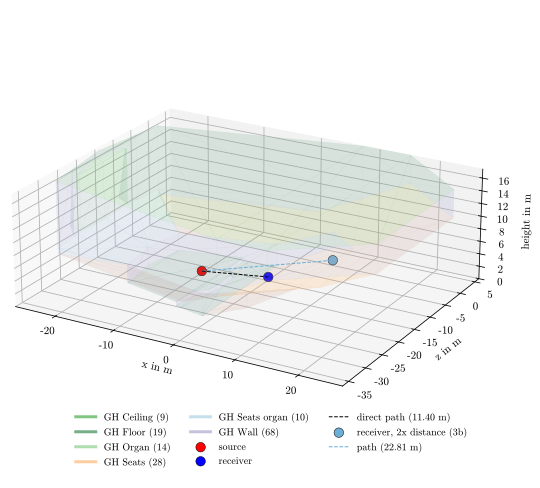

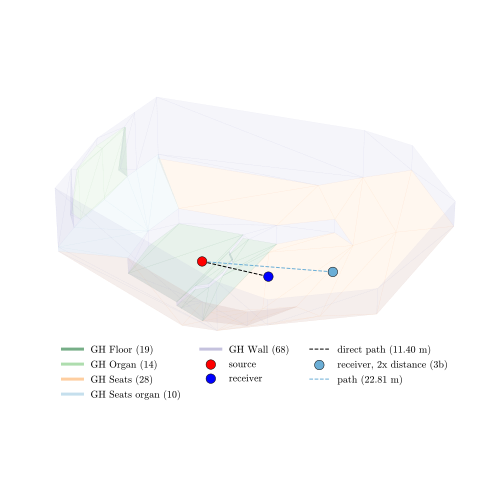

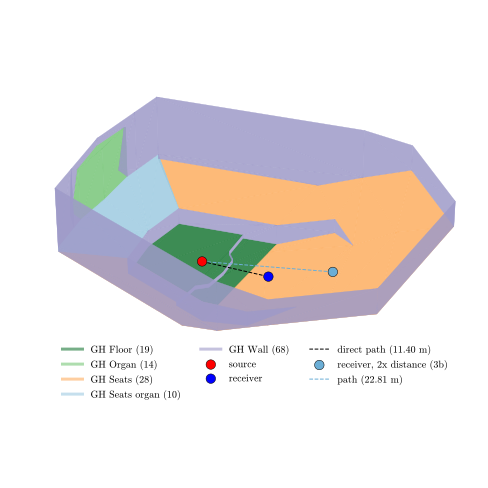

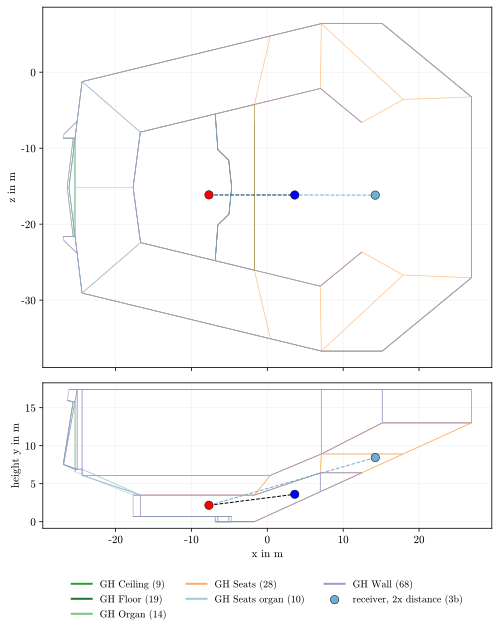

In [2]:
import pra_comparison_gewandhaus as gw

triangles = {name: gw._load_mesh_triangles(name) for name in gw.RICHTER_MATERIALS_20HZ}
source, mic = gw.GEWANDHAUS_CANONICAL["source_pos"], gw.GEWANDHAUS_CANONICAL["mic_pos"]
# one colour per material across all four figures (the default cycle is positional, so
# leaving out the ceiling would otherwise shift every colour in the open views)
palette = [plots.MISUKA_COLOR, plots.MISUKA_COLOR_ALT, plots.MISUKA_COLOR_ALT2,
           plots.PRA_COLOR_ALT, "#9ecae1", "#9e9ac8"]
colors = dict(zip(triangles, palette))
# receiver of the doubled-distance inverse variant (3b), not a GRAP position
extra = {"receiver, 2x distance (3b)": gw.DISTANCE_DOUBLE_MIC_POS}

fig, _ = plots.plot_mesh_geometry_3d(triangles, source, mic, group_colors=colors, extra_receivers=extra)
save_figure(fig, "atmo_gewandhaus_geometry")
# the ceiling removed, so the hall can be seen into
fig, _ = plots.plot_mesh_geometry_3d(triangles, source, mic, elev=36, exclude_groups=("GH_Ceiling",), group_colors=colors, extra_receivers=extra,
                                     show_axes=False, markers_on_top=True)
save_figure(fig, "atmo_gewandhaus_geometry_open")
fig, _ = plots.plot_mesh_geometry_3d(triangles, source, mic, elev=36, exclude_groups=("GH_Ceiling",), group_colors=colors, extra_receivers=extra,
                                     show_axes=False, face_alpha=0.85, markers_on_top=True)
# cropped to the drawn content, so the figure centres on the page
save_figure(fig, "atmo_gewandhaus_geometry_open_opaque", bbox_inches=plots.content_bbox(fig))
fig, _ = plots.plot_mesh_sections(triangles, source, mic, group_colors=colors, extra_receivers=extra)
save_figure(fig, "atmo_gewandhaus_sections")
plt.show()

## 1. Inline vs. post-processing attenuation

Post-processing attenuates each time bin's *already-summed* energy using the distance that bin's
time implies, while inline attenuation applies the correct per-path distance before any binning
happens. The difference between the two is the error under study here.

### 1a. Frequency dependence

The error is scaled by the ISO 9613-1 attenuation coefficient, which itself grows with $f^2$ -- so
the same per-bin distance ambiguity buys a progressively larger energy error at higher frequencies.

/Users/timon/Documents/Timon/Uni/SoSe26/Bachelor-Arbeit/benchmaring/tests/pra_comparison_plots.py:1276: UserWarning: cmr10 font should ideally be used with mathtext, set axes.formatter.use_mathtext to True
  fig, ax = plt.subplots(figsize=(6, 4))


saved /Users/timon/Documents/Timon/Uni/SoSe26/Bachelor Arbeit/BA/BA-tex/images/results/atmo_attenuation_frequency.svg


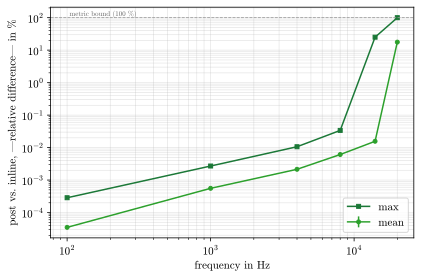

frequency [Hz],mean |difference| [%],max |difference| [%]
100.0000,0.0000,0.0003
1000.0000,0.0006,0.0027
4000.0000,0.0021,0.0106
8000.0000,0.0061,0.0338
14000.0000,0.0157,25.1150
20000.0000,17.6820,100.0000


In [3]:
run = load("atmospheric_attenuation_frequency")
fig = save_figure(plots.plot_attenuation_frequency_dependence(SCENARIO, run),
                  "atmo_attenuation_frequency")
plt.show()

metrics = run["metadata"]["metrics"]
pd.DataFrame({
    "frequency [Hz]": run["arrays"]["frequencies_hz"],
    "mean |difference| [%]": metrics["mean_abs_pct_by_frequency"],
    "max |difference| [%]": metrics["max_abs_pct_by_frequency"],
}).style.format(precision=4).hide(axis="index")

### 1b. Bin-width dependence

The distance approximation post-processing performs is a function of the bin width. Measured here
as $\max |t_{real} - \Delta t_i|$ and $\mathrm{avg} |t_{real} - \Delta t_i|$, the gap between a
path's true arrival time and the bin time its energy is attenuated by -- shown separately per
frequency (avg/max share a colour per frequency and differ only by marker).

Obtained from one high-resolution reference render (8x the suite's sampling rate) *with* inline
attenuation applied, re-binned to each candidate bin width -- misuka does not expose individual
path lengths, so the true arrival distribution is taken from the finest available resolution.
Rendering the reference with attenuation on (rather than raw) lets the per-frequency curves differ
at all: attenuation shifts energy earlier in time more aggressively at higher frequencies, so a
higher band's tail carries less weight and its errors count for less. The average is
energy-weighted for the same reason: an error in a bin carrying no energy cannot affect the
attenuated ETC.

/Users/timon/Documents/Timon/Uni/SoSe26/Bachelor-Arbeit/benchmaring/tests/pra_comparison_plots.py:1343: UserWarning: cmr10 font should ideally be used with mathtext, set axes.formatter.use_mathtext to True
  fig, ax = plt.subplots(figsize=(6.5, 4.5))
/Users/timon/Documents/Timon/Uni/SoSe26/Bachelor-Arbeit/benchmaring/tests/pra_comparison_plots.py:1313: UserWarning: cmr10 font should ideally be used with mathtext, set axes.formatter.use_mathtext to True
  sampling_axis = ax.secondary_xaxis(
/Users/timon/Documents/Timon/Uni/SoSe26/Bachelor-Arbeit/benchmaring/tests/pra_comparison_plots.py:1357: UserWarning: cmr10 font should ideally be used with mathtext, set axes.formatter.use_mathtext to True
  secondary = ax.secondary_yaxis(


saved /Users/timon/Documents/Timon/Uni/SoSe26/Bachelor Arbeit/BA/BA-tex/images/results/atmo_attenuation_bin_width.svg


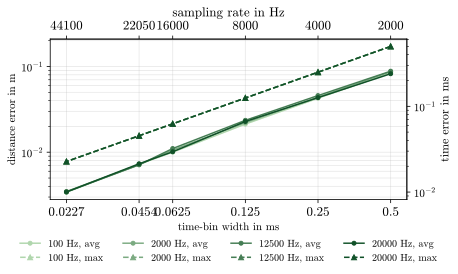

bin width [ms],sampling rate [Hz],frequency [Hz],max error [m],avg error [m]
0.5000,2000.0000,100.0000,0.1716,0.0844
0.5000,2000.0000,2000.0000,0.1716,0.0870
0.5000,2000.0000,12500.0000,0.1716,0.0882
0.5000,2000.0000,20000.0000,0.1716,0.0823
0.2500,4000.0000,100.0000,0.0858,0.0427
0.2500,4000.0000,2000.0000,0.0858,0.0439
0.2500,4000.0000,12500.0000,0.0858,0.0458
0.2500,4000.0000,20000.0000,0.0858,0.0433
0.1250,8000.0000,100.0000,0.0429,0.0213
0.1250,8000.0000,2000.0000,0.0429,0.0221


In [4]:
run = load("atmospheric_attenuation_bin_width")
fig = save_figure(plots.plot_attenuation_bin_width(SCENARIO, run),
                  "atmo_attenuation_bin_width")
plt.show()

arrays = run["arrays"]
frequencies = arrays["frequencies_hz"]
rows = []
for i, bw_ms in enumerate(arrays["bin_widths_s"] * 1e3):
    for j, freq in enumerate(frequencies):
        rows.append({
            "bin width [ms]": bw_ms,
            "sampling rate [Hz]": arrays["bin_widths_hz"][i],
            "frequency [Hz]": freq,
            "max error [m]": arrays["max_err_m"][i, j],
            "avg error [m]": arrays["avg_err_m"][i, j],
        })
pd.DataFrame(rows).style.format(precision=4).hide(axis="index")

### 1c. Postprocessing error vs. bin width

The same bin-width sweep as 1b, but measuring the error of the ETC itself: the energy-weighted
error eps = sum|H_post - H_inline| / sum H_inline (%) of postprocessing against inline attenuation,
with the distance of the bin start (as misuka's former postprocessing did) and of the bin centre.
Unlike 1b, each point here is a real render *at* that bin width (the scene's own sampling rate),
not a re-binning of one reference -- so the render cost scales with the number of bin widths, not
just the number of frequencies. eps between two inline renders with different seeds gives the
Monte Carlo noise of one render for scale (table only, not in the figure).

saved /Users/timon/Documents/Timon/Uni/SoSe26/Bachelor Arbeit/BA/BA-tex/images/results/atmo_attenuation_bin_width_etc_error.svg


/Users/timon/Documents/Timon/Uni/SoSe26/Bachelor-Arbeit/benchmaring/tests/pra_comparison_plots.py:1420: UserWarning: cmr10 font should ideally be used with mathtext, set axes.formatter.use_mathtext to True
  fig, ax = plt.subplots(figsize=(10, 4.5))
/Users/timon/Documents/Timon/Uni/SoSe26/Bachelor-Arbeit/benchmaring/tests/pra_comparison_plots.py:1313: UserWarning: cmr10 font should ideally be used with mathtext, set axes.formatter.use_mathtext to True
  sampling_axis = ax.secondary_xaxis(


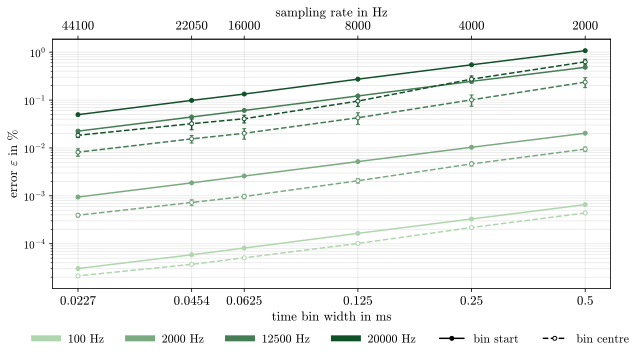

bin width [ms],sampling rate [Hz],frequency [Hz],"eps, bin start [%]","eps, bin centre [%]","total energy, bin start [%]","eps, Monte Carlo noise [%]"
0.5000,2000.0000,100.0000,0.0007,0.0004,0.0006,105.6095
0.5000,2000.0000,2000.0000,0.0203,0.0094,0.0195,72.4907
0.5000,2000.0000,12500.0000,0.4831,0.2371,0.4702,52.2657
0.5000,2000.0000,20000.0000,1.0736,0.6278,1.0408,31.8867
0.2500,4000.0000,100.0000,0.0003,0.0002,0.0003,114.3412
0.2500,4000.0000,2000.0000,0.0103,0.0046,0.0098,76.9708
0.2500,4000.0000,12500.0000,0.2458,0.1009,0.2357,56.0908
0.2500,4000.0000,20000.0000,0.5445,0.2728,0.5192,35.6654
0.1250,8000.0000,100.0000,0.0002,0.0001,0.0001,124.4546
0.1250,8000.0000,2000.0000,0.0052,0.0021,0.0049,82.1296


In [5]:
run = load("atmospheric_attenuation_bin_width_etc_error")
fig = save_figure(plots.plot_attenuation_bin_width_eps(SCENARIO, run),
                  "atmo_attenuation_bin_width_etc_error")
plt.show()

arrays = run["arrays"]
frequencies = arrays["frequencies_hz"]
rows = []
for i, bw_ms in enumerate(arrays["bin_widths_s"] * 1e3):
    for j, freq in enumerate(frequencies):
        rows.append({
            "bin width [ms]": bw_ms,
            "sampling rate [Hz]": arrays["bin_widths_hz"][i],
            "frequency [Hz]": freq,
            "eps, bin start [%]": arrays["eps_pct"][i, j],
            "eps, bin centre [%]": arrays["eps_pct_centre"][i, j],
            "total energy, bin start [%]": arrays["energy_pct"][i, j],
            "eps, Monte Carlo noise [%]": arrays["eps_noise_pct"][i, j],
        })
pd.DataFrame(rows).style.format(precision=4).hide(axis="index")

### 1d. Runtime

Inline attenuation computes the attenuation coefficient and applies it to every ray, so it may cost
runtime. Repeated-measures comparison: the same scene rendered 100 times with different seeds per
variant, on a MacBook Pro (M3 Pro).

Measured under the **scalar** variant, not LLVM. Timing is what this block measures, and the scalar
variant is single-threaded and JIT-free (`compare_atmosphere()`'s own docstring already assumes it),
whereas under LLVM every sample is spread over all 11 cores (~970 % CPU) and the scheduling noise
that introduces is larger than the effect under test. The price is wall-clock time: ~8.6 s per
render instead of ~0.87 s.

The three samples are paired (one seed renders all three variants), so paired tests apply. The
stored run keeps both a paired t-test and a Wilcoxon signed-rank result, plus a Shapiro-Wilk check
on the paired differences that decides which of the two is quoted.

/Users/timon/Documents/Timon/Uni/SoSe26/Bachelor-Arbeit/benchmaring/tests/pra_comparison_plots.py:1456: UserWarning: cmr10 font should ideally be used with mathtext, set axes.formatter.use_mathtext to True
  fig, ax = plt.subplots(figsize=(7, 2.5))


saved /Users/timon/Documents/Timon/Uni/SoSe26/Bachelor Arbeit/BA/BA-tex/images/results/atmo_attenuation_runtime.svg


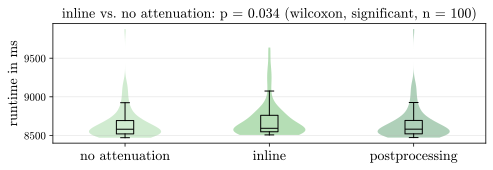

comparison,mean difference [ms],test,p,significant (p<0.05)
inline vs. no attenuation,45.9975,wilcoxon,0.0342,True
inline vs. post-processing,44.5848,wilcoxon,0.0425,True
post-processing vs. no attenuation,1.4127,wilcoxon,0.0000,True


variant,mean [ms],median [ms],std [ms]
no attenuation,8643.21,8579.22,200.40
inline,8689.21,8591.79,225.18
post-processing,8644.62,8580.54,200.43


In [6]:
run = load("atmospheric_attenuation_runtime")
fig = save_figure(plots.plot_attenuation_runtime(SCENARIO, run),
                  "atmo_attenuation_runtime")
plt.show()

metrics = run["metadata"]["metrics"]
rows = []
for tag, label in [("inline_vs_none", "inline vs. no attenuation"),
                   ("inline_vs_post", "inline vs. post-processing"),
                   ("post_vs_none", "post-processing vs. no attenuation")]:
    rows.append({
        "comparison": label,
        "mean difference [ms]": metrics[f"{tag}_mean_diff_ms"],
        "test": metrics[f"{tag}_test"],
        "p": metrics[f"{tag}_p"],
        "significant (p<0.05)": metrics[f"{tag}_p"] < 0.05,
    })
display(pd.DataFrame(rows).style.format(precision=4).hide(axis="index"))

pd.DataFrame([{
    "variant": name,
    "mean [ms]": metrics[f"runtime_{key}_ms_mean"],
    "median [ms]": metrics[f"runtime_{key}_ms_median"],
    "std [ms]": metrics[f"runtime_{key}_ms_std"],
} for key, name in [("none", "no attenuation"), ("inline", "inline"),
                    ("post", "post-processing")]]).style.format(precision=2).hide(axis="index")

## 2. Speed of sound

The methods introduce no additional runtime complexity: each is $O(1)$ and applied once per render
(it sets the integrator's speed of sound; it does not run per path or per sample). Only their
accuracy is therefore of interest.

pyroomacoustics and similar tools use the ISO 9613-1 formula, which depends on temperature alone.
The question is how far misuka's `cramer` / `ideal_gas` -- which also see humidity and CO$_2$ --
can drift from it. A global optimizer (`scipy.optimize.differential_evolution`) searches the
realistic indoor range: CO$_2$ 500-2000 ppm, relative humidity 20-70 %, temperature 5-30 °C,
pressure fixed at 101325 Pa, saturation vapour pressure from the Magnus formula.

> **Reading the numbers:** the headline figure is a *difference* in m/s, not a speed of sound. The
> absolute speeds are ~350 m/s, exactly as expected for 30 °C -- see the second table below.

/Users/timon/Documents/Timon/Uni/SoSe26/Bachelor-Arbeit/benchmaring/tests/pra_comparison_plots.py:1496: UserWarning: cmr10 font should ideally be used with mathtext, set axes.formatter.use_mathtext to True
  fig, axs = plt.subplots(1, len(methods), figsize=(2.7 * len(methods) + 0.6, 3.1),
/Users/timon/Documents/Timon/Uni/SoSe26/Bachelor-Arbeit/benchmaring/tests/pra_comparison_plots.py:1511: UserWarning: cmr10 font should ideally be used with mathtext, set axes.formatter.use_mathtext to True
  fig.colorbar(mesh, ax=axs[0].tolist(), location="right", fraction=0.05, pad=0.03,


saved /Users/timon/Documents/Timon/Uni/SoSe26/Bachelor Arbeit/BA/BA-tex/images/results/atmo_speed_of_sound_extremes.svg


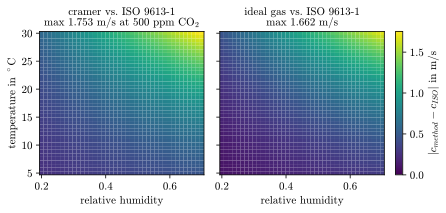

method,max |c_method - c_ISO| [m/s],temperature [°C],relative humidity,CO2 [ppm]
cramer,1.7531,30.0000,0.7000,500.2502
ideal_gas,1.6622,29.9998,0.7000,1453.2237


method,c_method [m/s],c_ISO [m/s],difference [m/s],relative difference [%]
cramer,350.7577,349.0046,1.7531,0.5023
ideal_gas,350.6667,349.0045,1.6622,0.4763


In [7]:
run = load("atmospheric_speed_of_sound_extremes")
fig = save_figure(plots.plot_speed_of_sound_extremes(SCENARIO, run, cmap="viridis"),
                  "atmo_speed_of_sound_extremes")
plt.show()

metrics = run["metadata"]["metrics"]
methods = ["cramer", "ideal_gas"]
display(pd.DataFrame([{
    "method": m,
    "max |c_method - c_ISO| [m/s]": metrics[f"{m}_max_abs_difference_ms"],
    "temperature [°C]": metrics[f"{m}_temperature_c"],
    "relative humidity": metrics[f"{m}_relative_humidity"],
    "CO2 [ppm]": metrics[f"{m}_co2_ppm"],
} for m in methods]).style.format(precision=4).hide(axis="index"))

# The absolute speeds at those worst-case points -- all ~350 m/s.
pd.DataFrame([{
    "method": m,
    "c_method [m/s]": metrics[f"{m}_speed_of_sound_method_ms"],
    "c_ISO [m/s]": metrics[f"{m}_speed_of_sound_iso_ms"],
    "difference [m/s]": metrics[f"{m}_max_abs_difference_ms"],
    "relative difference [%]": 100 * metrics[f"{m}_max_abs_difference_ms"]
                               / metrics[f"{m}_speed_of_sound_iso_ms"],
} for m in methods]).style.format(precision=4).hide(axis="index")

## 3. Inverse atmospheric rendering

Gradient-based retrieval of medium parameters from a rendered ETC, following
`tutorials_acoustic/inverse_rendering/atmosphere_optimization.ipynb` (`acoustic_prb` + `mi.traverse`
+ `mi.ad.Adam`, common random numbers between reference and current render) -- but on the Gewandhaus
scene, so attenuation acts along every reflected path rather than a single free-field one.

`speed_of_sound` is pinned, so the optimised parameter reaches the render *only* through air
attenuation. Two deviations from the tutorial were necessary here and are documented in
`atmospheric_evaluation.py`: `apply_attenuation=True` must be set explicitly (without it the
gradient is exactly zero), and the loss is relative rather than absolute (this room's spp-normalised
ETC makes the absolute loss ~1e-14, whose gradient falls below Adam's epsilon).

Each figure uses the three-panel layout: retrieved parameter over the iterations, loss over the
iterations, and reconstructed vs. target ETC.

### 3a. General retrieval

Temperature (goal 30 °C from a 10 °C guess) and relative humidity (goal 0.7 from 0.2), optimised
separately.

/Users/timon/Documents/Timon/Uni/SoSe26/Bachelor-Arbeit/benchmaring/tests/pra_comparison_plots.py:1545: UserWarning: cmr10 font should ideally be used with mathtext, set axes.formatter.use_mathtext to True
  fig, grid = plt.subplots(2, 2, figsize=(6.6, 4.2), layout="constrained",
/Users/timon/Documents/Timon/Uni/SoSe26/Bachelor-Arbeit/benchmaring/tests/pra_comparison_plots.py:1646: UserWarning: cmr10 font should ideally be used with mathtext, set axes.formatter.use_mathtext to True
  axins = axs[2].inset_axes(etc_zoom_inset_bounds)


saved /Users/timon/Documents/Timon/Uni/SoSe26/Bachelor Arbeit/BA/BA-tex/images/results/atmo_inverse_temperature.svg


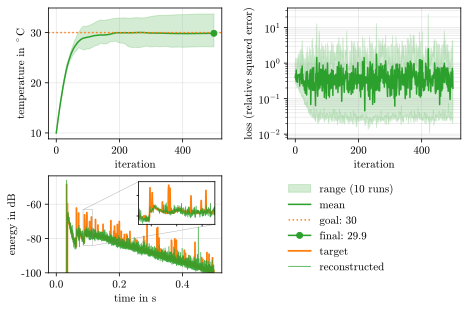

saved /Users/timon/Documents/Timon/Uni/SoSe26/Bachelor Arbeit/BA/BA-tex/images/results/atmo_inverse_relative_humidity.svg


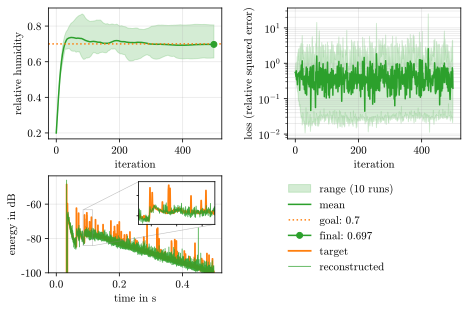

,run,goal,final,abs. error,final std,final change (max),distance in m,frequency in Hz,runtime per run in s
0,temperature,30.000,29.862,0.138,1.960,0.096,11.403,8000.000,80.200
1,relative_humidity,0.700,0.697,0.003,0.051,0.006,11.403,8000.000,75.326


In [8]:
records = []
for variant in ["temperature", "relative_humidity"]:
    run = load("atmospheric_inverse_retrieval", variant)
    fig = plots.plot_inverse_rendering(SCENARIO, run)
    save_figure(fig, f"atmo_inverse_{variant}")
    plt.show()
    records.append((variant, run["metadata"]["metrics"]))

plots.inverse_convergence_table(records)

saved /Users/timon/Documents/Timon/Uni/SoSe26/Bachelor Arbeit/BA/BA-tex/images/results/atmo_inverse_distance_half.svg


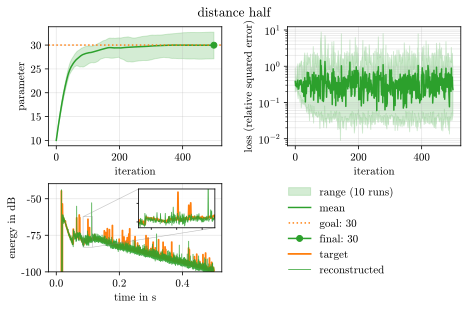

saved /Users/timon/Documents/Timon/Uni/SoSe26/Bachelor Arbeit/BA/BA-tex/images/results/atmo_inverse_distance_double.svg


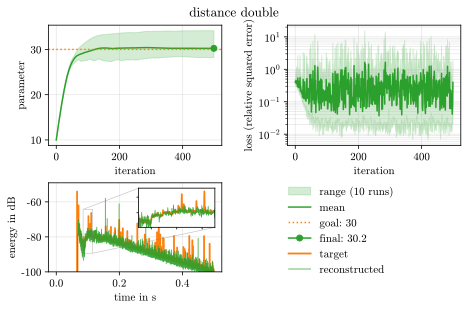

saved /Users/timon/Documents/Timon/Uni/SoSe26/Bachelor Arbeit/BA/BA-tex/images/results/atmo_inverse_frequency_half.svg


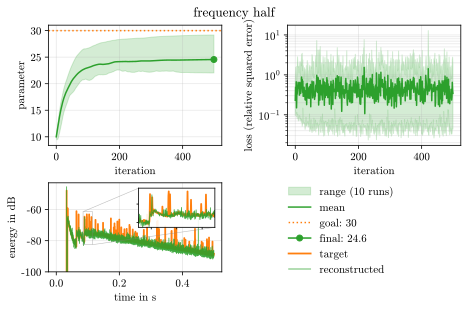

saved /Users/timon/Documents/Timon/Uni/SoSe26/Bachelor Arbeit/BA/BA-tex/images/results/atmo_inverse_frequency_double.svg


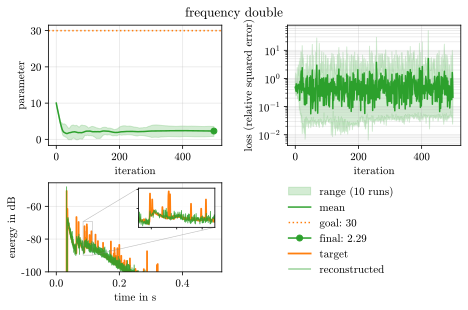

,run,goal,final,abs. error,final std,final change (max),distance in m,frequency in Hz,runtime per run in s
0,distance_half,30.000,29.975,0.025,1.488,0.085,5.701,8000.000,79.190
1,distance_double,30.000,30.234,0.234,1.671,0.180,22.805,8000.000,82.177
2,frequency_half,30.000,24.557,5.443,2.022,0.112,11.403,4000.000,78.884
3,frequency_double,30.000,2.294,27.706,0.775,0.097,11.403,16000.000,77.611


In [9]:
records = []
for variant in ["distance_half", "distance_double", "frequency_half", "frequency_double"]:
    run = load("atmospheric_inverse_distance_frequency", variant)
    fig = plots.plot_inverse_rendering(SCENARIO, run)
    fig.suptitle(variant.replace("_", " "))
    save_figure(fig, f"atmo_inverse_{variant}")
    plt.show()
    records.append((variant, run["metadata"]["metrics"]))

plots.inverse_convergence_table(records)

### 3c. Outside the validated parameter range

The inverse variants cannot enforce the input ranges the underlying formulas assume. Temperature is
set to -73 °C, outside the range where ISO 9613-1 still claims $\pm 50\,\%$ accuracy.

saved /Users/timon/Documents/Timon/Uni/SoSe26/Bachelor Arbeit/BA/BA-tex/images/results/atmo_inverse_out_of_range.svg


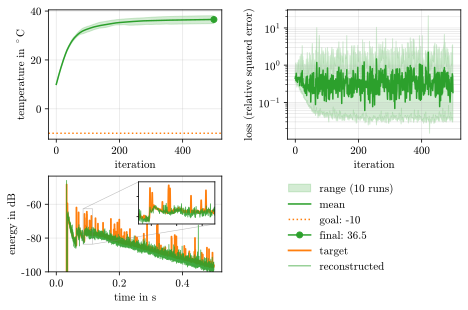

goal:      -10.00 °C
recovered: 36.54 °C
final change (last 50 iterations, max): 0.100 °C


In [10]:
run = load("atmospheric_inverse_out_of_range", "temperature_minus10")
fig = save_figure(plots.plot_inverse_rendering(SCENARIO, run),
                  "atmo_inverse_out_of_range")
plt.show()

metrics = run["metadata"]["metrics"]
print(f"goal:      {metrics['goal']:.2f} °C")
print(f"recovered: {metrics['final_value']:.2f} °C")
print(f"final change (last 50 iterations, max): {metrics['final_change_max']:.3f} °C")

The retrieval does not merely stall -- it converges to the *wrong* temperature. The reason is that
the attenuation coefficient is **not monotone** in temperature, so there is no descent direction
from the start point to the goal: a barrier, not a vanishing gradient.

saved /Users/timon/Documents/Timon/Uni/SoSe26/Bachelor Arbeit/BA/BA-tex/images/results/atmo_inverse_out_of_range_alpha.svg


/var/folders/f4/w7z9kmyn1hldhzn7_l6yrvtw0000gn/T/ipykernel_1424/2981889532.py:7: UserWarning: cmr10 font should ideally be used with mathtext, set axes.formatter.use_mathtext to True
  fig, ax = plt.subplots(figsize=(8, 4))


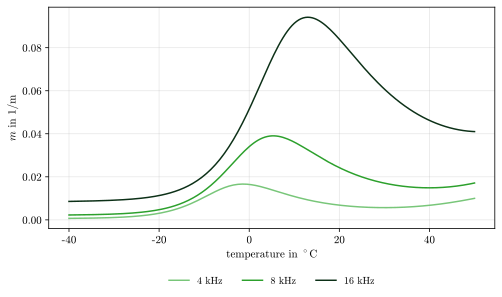

In [11]:
# Energy attenuation coefficient m(T) of the standard medium (50 % RH,
# 101325 Pa) at the three frequencies of the inverse experiments.
arrays = run["arrays"]
temperatures = arrays["alpha_temperatures_c"]
colors = [plots.MISUKA_COLOR_ALT2, plots.MISUKA_COLOR, plots.MISUKA_COLOR_ALT3]

fig, ax = plt.subplots(figsize=(8, 4))
for f, m, color in zip(arrays["alpha_frequencies_hz"], arrays["alpha_1_per_m_by_frequency"], colors):
    ax.plot(temperatures, m, color=color, label=f"{f / 1e3:g} kHz")
ax.set_xlabel(r"temperature in $^\circ$C")
ax.set_ylabel(r"$m$ in 1/m")
ax.legend(fontsize=10, ncol=3, loc="lower center", bbox_to_anchor=(0.5, -0.3), frameon=False)
ax.grid(True, alpha=0.3)
save_figure(fig, "atmo_inverse_out_of_range_alpha")
plt.show()

Descending from the start point, $\alpha$ *rises* towards a maximum near 0 °C and falls towards a
local minimum near the recovered value. The goal's coefficient lies far beyond that maximum, so
gradient descent cannot reach it from this initialisation.

### 3d. Joint retrieval of temperature and relative humidity

Both parameters optimised at the same time, towards a known goal (30 °C, 0.7), from six starts.
At a single frequency the render depends on the medium only through one attenuation coefficient --
one equation for two unknowns, so every point on the curve of equal attenuation (white) fits equally
well. With several bands (2, 8, 16 kHz) there is one such curve per band. The landscape is the same
loss as the optimisation, evaluated by attenuating one attenuation-free render per (T, RH)
(post-processing, accurate at this bin width, see block 1).

/Users/timon/Documents/Timon/Uni/SoSe26/Bachelor-Arbeit/benchmaring/tests/pra_comparison_plots.py:1960: UserWarning: cmr10 font should ideally be used with mathtext, set axes.formatter.use_mathtext to True
  fig, axs = plt.subplots(1, n, figsize=(4.4 * n, 4.2), layout="constrained",
/Users/timon/Documents/Timon/Uni/SoSe26/Bachelor-Arbeit/benchmaring/tests/pra_comparison_plots.py:1966: UserWarning: cmr10 font should ideally be used with mathtext, set axes.formatter.use_mathtext to True
  fig.colorbar(mesh, ax=ax, label=r"$\log_{10}$ loss")


saved /Users/timon/Documents/Timon/Uni/SoSe26/Bachelor Arbeit/BA/BA-tex/images/results/atmo_inverse_joint_single_frequency.svg


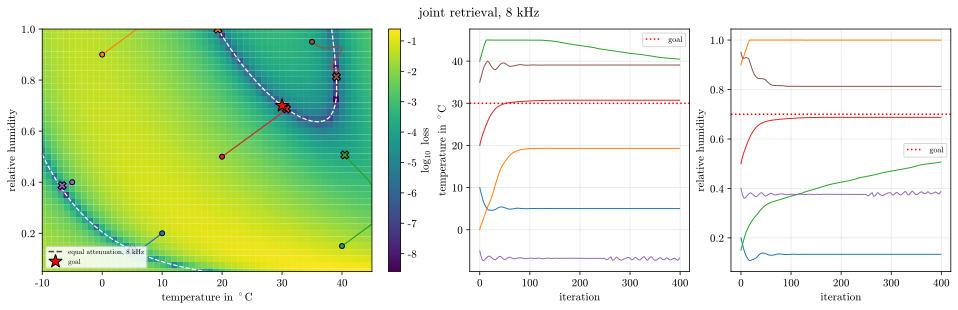

start T,start RH,final T,final RH,final loss
10.000,0.200,5.032,0.134,0.000
0.000,0.900,19.308,1.000,0.000
40.000,0.150,40.463,0.507,0.000
20.000,0.500,30.729,0.687,0.000
-5.000,0.400,-6.689,0.387,0.003
35.000,0.950,39.072,0.813,0.000


saved /Users/timon/Documents/Timon/Uni/SoSe26/Bachelor Arbeit/BA/BA-tex/images/results/atmo_inverse_joint_multi_frequency.svg


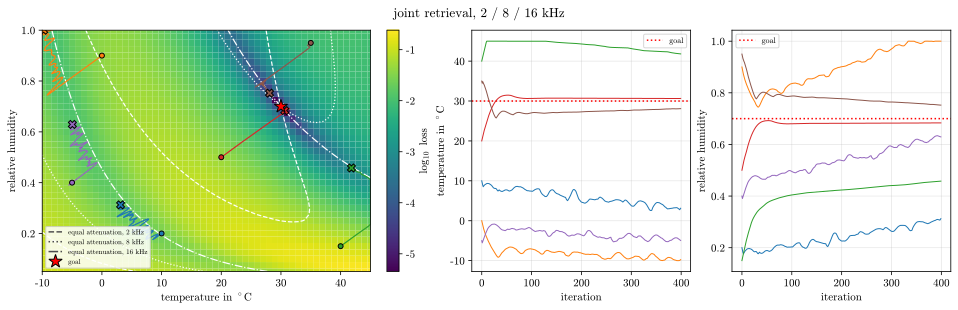

start T,start RH,final T,final RH,final loss
10.000,0.200,3.127,0.313,0.029
0.000,0.900,-9.765,1.000,0.020
40.000,0.150,41.810,0.458,0.001
20.000,0.500,30.640,0.684,0.000
-5.000,0.400,-4.954,0.629,0.032
35.000,0.950,28.085,0.752,0.000


In [12]:
for variant, title in [("single_frequency", "joint retrieval, 8 kHz"),
                       ("multi_frequency", "joint retrieval, 2 / 8 / 16 kHz")]:
    run = load("atmospheric_inverse_joint", variant)
    fig = save_figure(plots.plot_inverse_joint(run, title=title), f"atmo_inverse_joint_{variant}")
    plt.show()
    a = run["arrays"]
    display(pd.DataFrame({"start T": a["starts"][:, 0], "start RH": a["starts"][:, 1],
                          "final T": a["finals"][:, 0], "final RH": a["finals"][:, 1],
                          "final loss": a["losses"][:, -1]}).style.format(precision=3).hide(axis="index"))

### 3e. Retrieval from the RAVEN reference

The same retrieval, but against GRAP's RAVEN histogram for R1 (4, 8, 16 kHz) instead of a misuka
render: the target is external, so misuka's own modelling differences enter the result. Loss: mean
squared dB difference per band after removing the best level offset (misuka's and RAVEN's absolute
energies differ), from 50 ms on and down to 60 dB below the peak, in 10 ms bins. RAVEN's atmosphere
is not documented locally; the red star marks Richter's RAVEN standard conditions (20 °C, 50 %).
Temperature alone (RH fixed at 0.5), humidity alone (T fixed at 20 °C), and both jointly.

saved /Users/timon/Documents/Timon/Uni/SoSe26/Bachelor Arbeit/BA/BA-tex/images/results/atmo_inverse_raven_temperature.svg


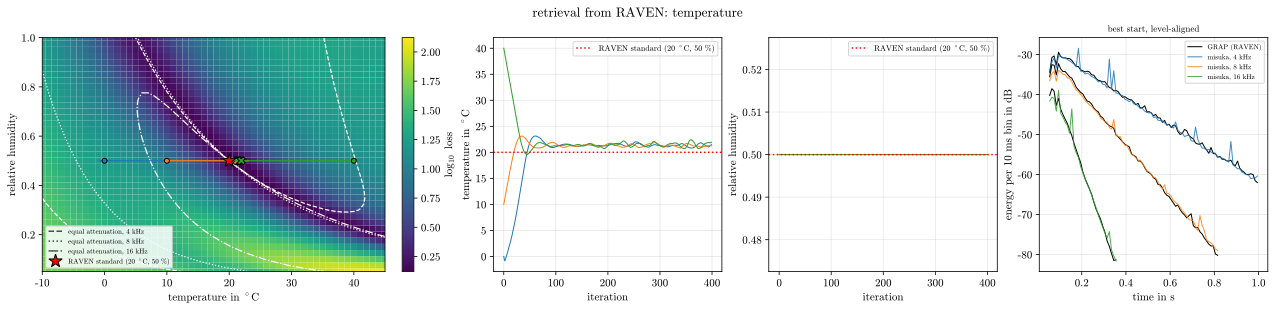

start T,start RH,final T,final RH,final loss
0.000,0.500,21.479,0.500,1.932
10.000,0.500,21.274,0.500,1.921
40.000,0.500,21.933,0.500,1.799


saved /Users/timon/Documents/Timon/Uni/SoSe26/Bachelor Arbeit/BA/BA-tex/images/results/atmo_inverse_raven_relative_humidity.svg


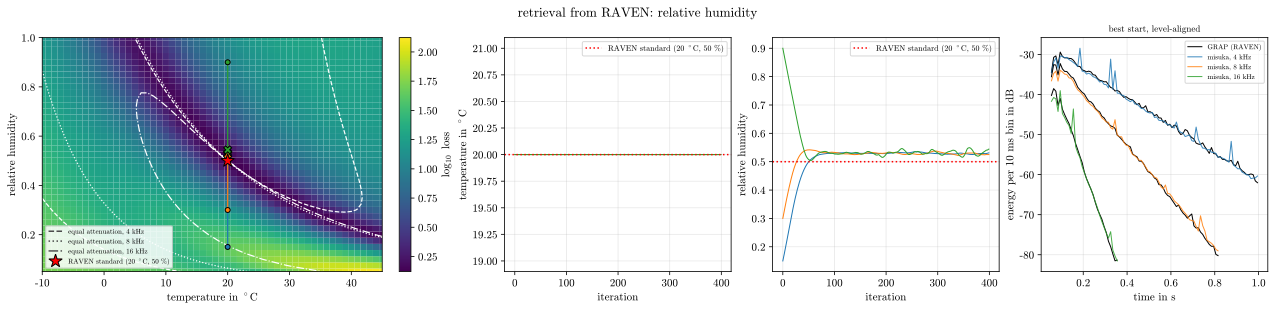

start T,start RH,final T,final RH,final loss
20.000,0.150,20.000,0.531,1.926
20.000,0.300,20.000,0.525,1.909
20.000,0.900,20.000,0.544,1.818


saved /Users/timon/Documents/Timon/Uni/SoSe26/Bachelor Arbeit/BA/BA-tex/images/results/atmo_inverse_raven_joint.svg


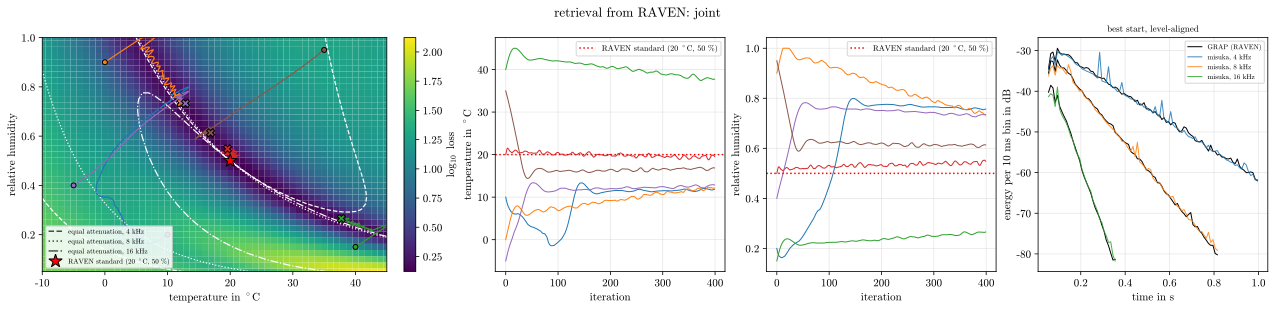

start T,start RH,final T,final RH,final loss
10.000,0.200,11.861,0.757,1.969
0.000,0.900,12.132,0.735,1.968
40.000,0.150,37.745,0.266,1.787
20.000,0.500,19.571,0.549,3.355
-5.000,0.400,12.864,0.733,1.089
35.000,0.950,16.864,0.614,1.830


In [13]:
for variant in ["temperature", "relative_humidity", "joint"]:
    run = load("atmospheric_inverse_raven", variant)
    fig = save_figure(plots.plot_inverse_joint(run, title=f"retrieval from RAVEN: {variant.replace('_', ' ')}",
                                               goal_label=r"RAVEN standard (20 $^\circ$C, 50 %)"),
                      f"atmo_inverse_raven_{variant}")
    plt.show()
    a = run["arrays"]
    display(pd.DataFrame({"start T": a["starts"][:, 0], "start RH": a["starts"][:, 1],
                          "final T": a["finals"][:, 0], "final RH": a["finals"][:, 1],
                          "final loss": a["losses"][:, -1]}).style.format(precision=3).hide(axis="index"))